In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

In [2]:
wholesale = pd.read_csv('Wholesale customers data.csv')
wholesale

,Channel,Region,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
0,2,3,12669,9656,7561,214,2674,1338
1,2,3,7057,9810,9568,1762,3293,1776
2,2,3,6353,8808,7684,2405,3516,7844
3,1,3,13265,1196,4221,6404,507,1788
4,2,3,22615,5410,7198,3915,1777,5185
...,...,...,...,...,...,...,...,...
435,1,3,29703,12051,16027,13135,182,2204
436,1,3,39228,1431,764,4510,93,2346
437,2,3,14531,15488,30243,437,14841,1867
438,1,3,10290,1981,2232,1038,168,2125


In [3]:
wholesale.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 440 entries, 0 to 439
Data columns (total 8 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   Channel           440 non-null    int64
 1   Region            440 non-null    int64
 2   Fresh             440 non-null    int64
 3   Milk              440 non-null    int64
 4   Grocery           440 non-null    int64
 5   Frozen            440 non-null    int64
 6   Detergents_Paper  440 non-null    int64
 7   Delicassen        440 non-null    int64
dtypes: int64(8)
memory usage: 27.6 KB


In [5]:
target = wholesale["Region"]
features = wholesale.drop("Region", axis=1)

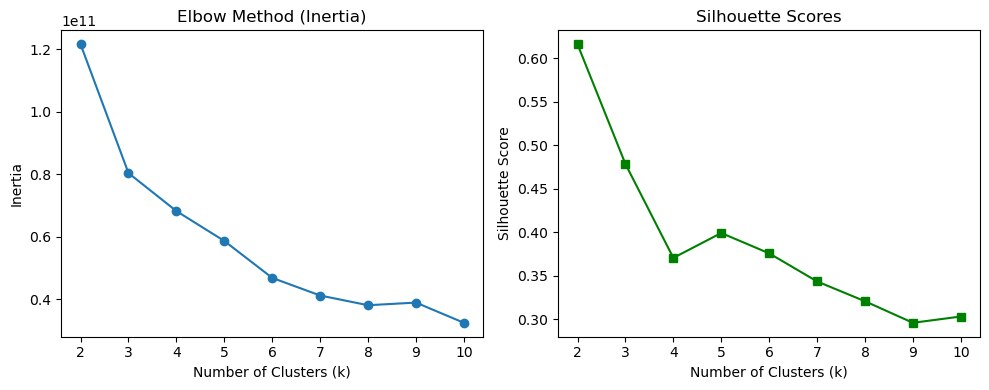

In [6]:
inertia_values = []
silhouette_scores = []
k_range = range(2, 11)

for k in k_range:
    model = KMeans(n_clusters=k, random_state=1)
    model.fit(features)
    inertia_values.append(model.inertia_)
    silhouette_scores.append(silhouette_score(features, model.labels_))

plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
plt.plot(k_range, inertia_values, marker='o')
plt.xlabel('Number of Clusters (k)')
plt.ylabel('Inertia')
plt.title('Elbow Method (Inertia)')

plt.subplot(1, 2, 2)
plt.plot(k_range, silhouette_scores, marker='s', color='green')
plt.xlabel('Number of Clusters (k)')
plt.ylabel('Silhouette Score')
plt.title('Silhouette Scores')

plt.tight_layout()
plt.show()

In [7]:
model = KMeans(n_clusters=2, random_state=1).fit(features)
target_predicted = model.labels_
silhouette_score(features, target_predicted)

np.float64(0.6158373894223493)

In [10]:
inertia_values

[121560056892.07288,
 80332413915.45752,
 68179751929.73634,
 58611157655.41923,
 46794283326.8943,
 41158638862.40411,
 38046920768.62806,
 38891257278.14711,
 32424503675.099327]

In [11]:
silhouette_scores

[np.float64(0.6158373894223493),
 np.float64(0.4783511427525112),
 np.float64(0.37047298406802115),
 np.float64(0.3990333277057523),
 np.float64(0.375687452671183),
 np.float64(0.34339688034953936),
 np.float64(0.320648681573971),
 np.float64(0.2958983552820015),
 np.float64(0.3031160934785213)]